# Survivorship bias and mean-reversion algorithms

The datasets bundled with this package (NYSE, DJIA, SP500, TSE, MSCI) are the standard benchmarks of the online portfolio selection literature. They only contain stocks that traded for the whole period: none went bankrupt or was delisted. Mean-reversion ("follow the loser") algorithms such as OLMAR, PAMR or PPT move money into stocks that have just fallen, so they are the ones most exposed to that selection. In survivor-only data, a stock that falls always recovers.

This notebook asks two questions on simulated data, where we know exactly what is in the prices:

1. **Does survivorship alone create the mean-reversion edge?** If the prices are random walks (no mean reversion at all) and we keep only the survivors, do these algorithms start beating uniform CRP?
2. **What does survivor-only data hide?** How do the same algorithms do when the universe includes stocks that go bankrupt?

Prices are zero-drift geometric random walks, so by construction there is nothing to predict. A stock is *bankrupt* the first day it falls below a barrier (a fraction of its starting price): it loses a further `loss` of its value that day and is then delisted, its price flat for the rest of the period. From each simulated pool of 2,000 stocks we draw three 30-stock universes:

- **no bankruptcy**: 30 random stocks, plain random walks;
- **with bankruptcy**: the same 30 stocks, with bankruptcy applied, which is what a realistic universe looks like;
- **survivors**: 30 random stocks among those that never crossed the barrier, which is what the benchmark datasets look like.

Every algorithm is compared with uniform CRP on the same universe. The comparison is in log-wealth, and the tables report it as final wealth relative to CRP's.

In [1]:
import itertools
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

from universal import algos

logging.disable(logging.CRITICAL)
warnings.simplefilter("ignore")

N_POOL, N_PICK = 2000, 30
ALGOS = {
    "CRP": algos.CRP,
    "BAH": algos.BAH,
    "EG": algos.EG,
    "OLMAR": algos.OLMAR,
    "PAMR": algos.PAMR,
    "PPT": algos.PPT,
}
MEAN_REVERSION = ["OLMAR", "PAMR", "PPT"]


def simulate(seed, sigma, T, barrier, loss):
    """Three universes of N_PICK stocks drawn from a pool of zero-drift random walks."""
    rng = np.random.default_rng(seed)
    P = np.exp(np.cumsum(rng.normal(0, sigma, (T, N_POOL)), axis=0))
    P = np.vstack([np.ones(N_POOL), P])
    crossed = P < barrier
    bankrupt = crossed.any(axis=0)
    # on the first day below the barrier lose `loss` of the value, then stay flat (delisted)
    P_bk = P.copy()
    for j in np.flatnonzero(bankrupt):
        tau = crossed[:, j].argmax()
        P_bk[tau:, j] = P[tau, j] * (1 - loss)
    pick = rng.choice(N_POOL, N_PICK, replace=False)
    pick_surv = rng.choice(np.flatnonzero(~bankrupt), N_PICK, replace=False)
    universes = {
        "no bankruptcy": pd.DataFrame(P[:, pick]),
        "with bankruptcy": pd.DataFrame(P_bk[:, pick]),
        "survivors": pd.DataFrame(P[:, pick_surv]),
    }
    return universes, bankrupt.mean()

What the two kinds of data look like: the 30 stocks of one simulated universe (daily volatility 3%, 1,000 days, barrier at 50% of the starting price). Survivor-only data only ever contains the grey paths.

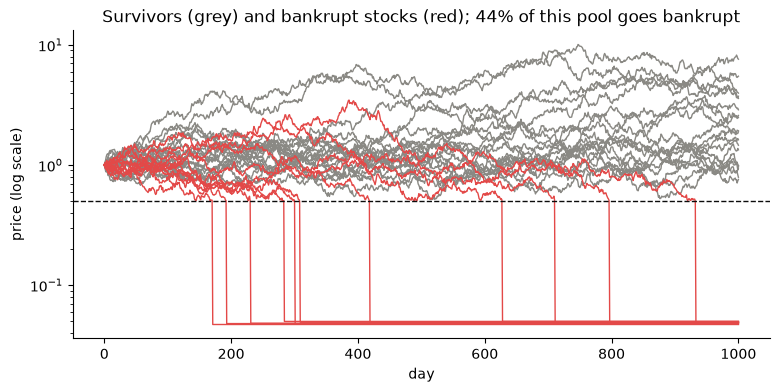

In [2]:
universes, rate = simulate(seed=0, sigma=0.03, T=1000, barrier=0.5, loss=0.9)
S = universes["with bankruptcy"]
dead = S.iloc[-1] < 0.5

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(S.loc[:, ~dead].iloc[:, :20], color="#8a8984", lw=1)
ax.plot(S.loc[:, dead].iloc[:, :20], color="#e34948", lw=1)
ax.axhline(0.5, color="#0b0b0b", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("day")
ax.set_ylabel("price (log scale)")
ax.set_title(f"Survivors (grey) and bankrupt stocks (red); {rate:.0%} of this pool goes bankrupt")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Running the grid

To check that the answer doesn't hinge on one setting, the simulation runs over a grid of volatilities, horizons and barriers (12 settings) with 20 seeds each, and for two bankruptcy losses: 90% (a typical bankruptcy) and a milder 50%. That is 480 simulated pools and 8,640 backtests. It takes about 3 minutes on a 10-core laptop.

In [3]:
SIGMAS, HORIZONS, BARRIERS, SEEDS = [0.02, 0.03], [500, 1000], [0.3, 0.5, 0.7], range(20)


def run_one(seed, sigma, T, barrier, loss):
    logging.disable(logging.CRITICAL)
    warnings.simplefilter("ignore")
    universes, bankrupt_rate = simulate(seed, sigma, T, barrier, loss)
    return [
        dict(loss=loss, sigma=sigma, T=T, barrier=barrier, seed=seed, bankrupt_rate=bankrupt_rate,
             universe=universe, algo=name, log_wealth=np.log(A().run(S).total_wealth))
        for universe, S in universes.items()
        for name, A in ALGOS.items()
    ]


grid = list(itertools.product(SEEDS, SIGMAS, HORIZONS, BARRIERS, [0.9, 0.5]))
rows = Parallel(n_jobs=-1)(delayed(run_one)(*g) for g in grid)
df = pd.DataFrame([r for rs in rows for r in rs])

# log-wealth relative to uniform CRP on the same universe
setting = ["loss", "sigma", "T", "barrier"]
wide = df.pivot_table(index=setting + ["seed", "universe"], columns="algo", values="log_wealth")
excess = wide.sub(wide["CRP"], axis=0).drop(columns="CRP")
excess.groupby("loss").size()

loss
0.5    720
0.9    720
dtype: int64

## Results

Final wealth relative to uniform CRP, averaged over all settings and seeds (the geometric mean, i.e. `exp` of the mean log-wealth difference). 100% means "same as CRP".

In [4]:
order = ["no bankruptcy", "survivors", "with bankruptcy"]
summary = np.exp(excess.groupby(["loss", "universe"]).mean()).T
summary = summary.reindex(columns=pd.MultiIndex.from_product([[0.9, 0.5], order]))
summary.style.format("{:.0%}")

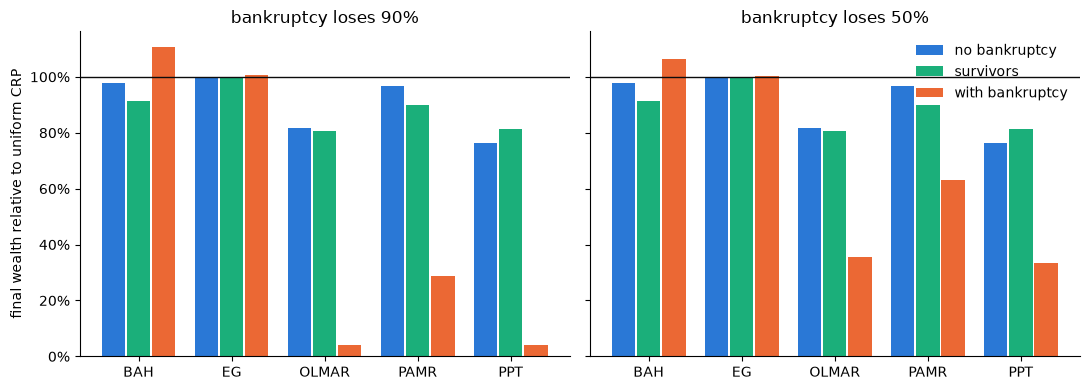

In [5]:
colors = {"no bankruptcy": "#2a78d6", "survivors": "#1baf7a", "with bankruptcy": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, loss in zip(axes, [0.9, 0.5]):
    data = summary[loss]
    x = np.arange(len(data))
    for k, universe in enumerate(order):
        ax.bar(x + (k - 1) * 0.27, data[universe], width=0.25, color=colors[universe], label=universe)
    ax.axhline(1, color="#0b0b0b", lw=1)
    ax.set_xticks(x, data.index)
    ax.set_title(f"bankruptcy loses {loss:.0%}")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("final wealth relative to uniform CRP")
axes[0].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

### Is it consistent across settings?

For each setting: how much better an algorithm does relative to CRP on survivors than on the universe with bankruptcies (difference in mean log-wealth, with a 95% interval over the 20 seeds). A positive value means survivor-only data makes the algorithm look better than it would be on a realistic universe.

In [6]:
stats = excess.stack().rename("excess").reset_index()
g = stats.groupby(setting + ["algo", "universe"])["excess"].agg(["mean", "var", "count"]).unstack("universe")
diff = g[("mean", "survivors")] - g[("mean", "with bankruptcy")]
se = np.sqrt(g[("var", "survivors")] / g[("count", "survivors")] + g[("var", "with bankruptcy")] / g[("count", "with bankruptcy")])
table = pd.DataFrame({"difference": diff, "lo": diff - 1.96 * se, "hi": diff + 1.96 * se})
table["sign"] = np.where(table.lo > 0, "better on survivors", np.where(table.hi < 0, "worse on survivors", "no clear difference"))

rate = df.groupby(setting)["bankrupt_rate"].mean().rename("bankrupt rate")
print(table.groupby(["loss", "algo"])["sign"].value_counts().unstack(fill_value=0).to_string())
table["difference"].unstack("algo").join(rate).round(2)

sign        better on survivors  no clear difference  worse on survivors
loss algo                                                               
0.5  BAH                      0                    2                  10
     EG                       0                    1                  11
     OLMAR                    6                    6                   0
     PAMR                     5                    7                   0
     PPT                      7                    5                   0
0.9  BAH                      0                    2                  10
     EG                       0                    0                  12
     OLMAR                   10                    2                   0
     PAMR                     8                    4                   0
     PPT                      9                    3                   0


BAH    EG  OLMAR  PAMR   PPT  bankrupt rate
loss sigma T    barrier                                              
0.5  0.02  500  0.3     -0.01 -0.00   0.13  0.06  0.05           0.01
                0.5     -0.05 -0.00   0.17  0.16  0.02           0.11
                0.7     -0.10 -0.00   1.44  0.85  1.37           0.41
           1000 0.3     -0.02 -0.00  -0.22 -0.08  0.05           0.05
                0.5     -0.14 -0.01   0.79  0.20  0.84           0.26
                0.7     -0.18 -0.01   1.26  0.61  1.50           0.56
     0.03  500  0.3     -0.07 -0.00   0.35  0.06  0.07           0.07
                0.5     -0.17 -0.01   0.52  0.30  0.58           0.29
                0.7     -0.21 -0.01   1.87  0.93  2.24           0.57
           1000 0.3     -0.19 -0.01   0.33 -0.11  0.35           0.20
                0.5     -0.31 -0.02   0.32  0.21  0.85           0.45
                0.7     -0.39 -0.02   2.92  1.07  2.76           0.69
0.9  0.02  500  0.3     -0.01 -0.00   0.12  0.06  0.05           0.01
                0.5     -0.08 -0.00   0.65  0.40  0.62           0.11
                0.7     -0.13 -0.01   4.43  2.50  4.26           0.41
           1000 0.3     -0.04 -0.00   0.09  0.09  0.20           0.05
                0.5     -0.19 -0.01   2.87  0.88  2.70           0.26
                0.7     -0.21 -0.01   4.99  1.91  4.60           0.56
     0.03  500  0.3     -0.09 -0.01   1.25  0.25  0.70           0.07
                0.5     -0.23 -0.01   1.83  0.83  2.16           0.29
                0.7     -0.24 -0.01   6.05  2.46  6.96           0.57
           1000 0.3     -0.24 -0.02   1.48  0.21  1.58           0.20
                0.5     -0.40 -0.02   2.22  1.01  2.93           0.45
                0.7     -0.44 -0.02   9.63  3.01  8.90           0.69

## Conclusions

**Survivorship alone does not create the mean-reversion edge.** On random walks, OLMAR, PAMR and PPT end with 81–90% of uniform CRP's wealth on survivor-only data, about where they are when nobody goes bankrupt (76–97%). Keeping only the survivors doesn't make them beat CRP. So the spectacular results these algorithms get on the benchmark datasets (OLMAR and PPT multiply wealth by about 10¹⁷–10¹⁸ on NYSE(O) before costs) can't be explained by the selection alone in this model. They have to come from short-term reversal that is really in those historical prices, and whether that reversal could have been traded after costs and bid-ask spreads is a separate question.

**What survivorship does is hide the downside.** In a universe where stocks really go bankrupt, the same algorithms keep buying into the collapsing stocks:

- With a 90% bankruptcy loss, OLMAR and PPT end with about 4% of CRP's wealth and PAMR with 29%.
- With a milder 50% loss, they end with 33–63%.
- Buy-and-hold does slightly *better* with bankruptcies than without, because it never adds to a falling stock. EG is unaffected.

The gap grows with the bankruptcy rate. Across the 12 settings, the mean-reversion algorithms look better on survivors than on the realistic universe in 8–10 settings with a 90% loss and 5–7 with a 50% loss. They never look worse; the remaining settings, mostly those where almost no stock goes bankrupt, show no clear difference.

So a backtest on survivor-only data overstates follow-the-loser algorithms. It removes the stocks that fall and don't come back, which are exactly the stocks those algorithms pile into.

**Limits of this experiment.** Prices are independent random walks, bankruptcy is a simple barrier, every algorithm runs with its default parameters, and there are no transaction costs. It shows a mechanism, not the size of the effect on any real market.